# Internações por mês e por estado, e previsão com LSTM

Cada ponto da série é o número de AIHs normais (`IDENT` = 1) cuja **data de internação** (`DT_INTER`) cai naquele mês, no **estado do hospital**. Os arquivos do SIH vêm organizados pelo mês de faturamento, que não é o mês da internação: uma AIH de janeiro pode ser lançada meses depois. Por isso o notebook lê os arquivos e reagrupa pela data de internação.

Arquivos usados: SIH-RD, janeiro de 2008 a setembro de 2026, as 27 UFs. A série que entra no modelo vai de **julho de 2008 a março de 2026**. Os seis primeiros meses compensam internações de 2008 lançadas ainda em 2007, e os seis últimos ficam de fora porque ainda vão receber lançamentos atrasados.

A LSTM prevê os **12 meses seguintes** de cada estado. Primeiro ela é avaliada nos últimos 12 meses já conhecidos (abril de 2025 a março de 2026). Depois é reestimada com toda a série confiável e projeta **abril de 2026 a março de 2027**.

A leitura baixa um arquivo por UF e mês. São cerca de 6 mil arquivos e a primeira execução leva horas. O que já foi contado fica em `dados/contagens/` e não é baixado de novo.

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import nest_asyncio
import numpy as np
import pandas as pd
import torch
from torch import nn

nest_asyncio.apply()

from datasus import UFS, internacoes

PASTA = Path("dados")
CONTAGENS = PASTA / "contagens"
CONTAGENS.mkdir(parents=True, exist_ok=True)

ANO_INICIO = 2008
ANO_FIM = 2026
MES_FIM = 9
MESES_BORDA = 6
JANELA = 24
HORIZONTE = 12
SEMENTE = 42

torch.manual_seed(SEMENTE)
np.random.seed(SEMENTE)
plt.rcParams["figure.figsize"] = (11, 4)
print(f"{len(UFS)} UFs. Contagens em {CONTAGENS.resolve()}")

27 UFs. Contagens em C:\Users\emano\OneDrive\Documentos\doutorado\sus\dados\contagens


In [5]:
def meses_do_ano(ano: int) -> list[int]:
    if ano < ANO_FIM:
        return list(range(1, 13))
    if ano == ANO_FIM:
        return list(range(1, MES_FIM + 1))
    return []


def baixar_ano(uf: str, ano: int) -> pd.DataFrame:
    meses = meses_do_ano(ano)
    try:
        return internacoes(
            uf=uf,
            ano=ano,
            meses=meses,
            grupo="RD",
            colunas=["DT_INTER", "IDENT"],
        )
    except Exception as erro_ano:
        print(f"  {uf} {ano}: o ano inteiro falhou ({erro_ano}). Tentando mês a mês.")
        partes = []
        for mes in meses:
            try:
                partes.append(
                    internacoes(
                        uf=uf,
                        ano=ano,
                        meses=mes,
                        grupo="RD",
                        colunas=["DT_INTER", "IDENT"],
                    )
                )
            except Exception as erro_mes:
                print(f"  {uf} {ano}-{mes:02d} falhou: {erro_mes}")
        if not partes:
            raise RuntimeError(f"Nenhum mês de {uf} {ano} foi lido.") from erro_ano
        return pd.concat(partes, ignore_index=True)


def contar_ano(uf: str, ano: int) -> pd.DataFrame:
    destino = CONTAGENS / f"{uf}_{ano}.parquet"
    if destino.exists():
        return pd.read_parquet(destino)

    bruto = baixar_ano(uf, ano)
    vazio = pd.DataFrame(columns=["uf", "mes", "internacoes"])
    if bruto.empty:
        vazio.to_parquet(destino, index=False)
        return vazio

    ident = bruto["IDENT"].astype(str).str.strip().str.lstrip("0")
    datas = bruto.loc[ident.eq("1"), "DT_INTER"].astype(str).str.slice(0, 6)
    datas = datas[datas.str.fullmatch(r"(?:19|20)\d{4}")]
    if datas.empty:
        vazio.to_parquet(destino, index=False)
        return vazio

    contagem = (
        datas.value_counts()
        .rename_axis("mes")
        .reset_index(name="internacoes")
    )
    contagem["uf"] = uf
    contagem = contagem[["uf", "mes", "internacoes"]]
    contagem.to_parquet(destino, index=False)
    return contagem

## Leitura

A célula abaixo percorre as 27 UFs e cada ano de 2008 a 2026. Pode interromper e rodar de novo: o arquivo `dados/contagens/UF_ANO.parquet` guarda a contagem daquele ano.

In [6]:
for uf in UFS:
    for ano in range(ANO_INICIO, ANO_FIM + 1):
        destino = CONTAGENS / f"{uf}_{ano}.parquet"
        if destino.exists():
            continue
        print(f"{uf} {ano}")
        contar_ano(uf, ano)

partes = [pd.read_parquet(caminho) for caminho in sorted(CONTAGENS.glob("*.parquet"))]
contagens = pd.concat(partes, ignore_index=True)
contagens = contagens[contagens["mes"].between("200801", "202609")]
serie = (
    contagens.groupby(["uf", "mes"], as_index=False)["internacoes"]
    .sum()
)
serie["mes"] = pd.to_datetime(serie["mes"], format="%Y%m")
serie.to_parquet(PASTA / "internacoes_mes_uf.parquet", index=False)
print(f"{len(serie):,} linhas UF-mês com internação registrada")
serie.head()

AC 2010




RDAC1012.parquet: 0.00B [00:00, ?B/s]


RDAC1011.parquet: 0.00B [00:00, ?B/s]2 [00:00<00:01,  6.48file/s]


RDAC1008.parquet: 0.00B [00:00, ?B/s]


RDAC1004.parquet: 0.00B [00:00, ?B/s]













RDAC1002.parquet: 100%|██████████| 225k/225k [00:00<00:00, 671kB/s]
RDAC1007.parquet: 100%|██████████| 240k/240k [00:00<00:00, 663kB/s]

RDAC1003.parquet: 0.00B [00:00, ?B/s]


RDAC1001.parquet: 100%|██████████| 262k/262k [00:00<00:00, 585kB/s]












RDAC1010.parquet: 100%|██████████| 231k/231k [00:00<00:00, 665kB/s]

RDAC1006.parquet: 100%|██████████| 246k/246k [00:00<00:00, 616kB/s]

RDAC1009.parquet: 0.00B [00:00, ?B/s]


RDAC1005.parquet: 100%|██████████| 261k/261k [00:00<00:00, 661kB/s]


AC 2011




















RDAC1110.parquet: 100%|██████████| 263k/263k [00:00<00:00, 661kB/s]

RDAC1112.parquet: 100%|██████████| 264k/264k [00:00<00:00, 565kB/s]
RDAC1111.parquet: 100%|██████████| 285k/285k [00:00<00:00, 544kB/s]













RDAC1104.parquet: 100%|██████████| 277k/277k [00:00<00:00, 646kB/s]




RDAC1107.parquet: 100%|██████████| 280k/280k [00:00<00:00, 636kB/s]


RDAC1102.parquet: 100%|██████████| 267k/267k [00:00<00:00, 619kB/s]









RDAC1103.parquet: 100%|██████████| 270k/270k [00:00<00:00, 644kB/s]





RDAC1108.parquet: 100%|██████████| 261k/261k [00:00<00:00, 664kB/s]




RDAC1101.parquet: 100%|██████████| 281k/281k [00:00<00:00, 662kB/s]















RDAC1109.parquet: 100%|██████████| 271k/271k [00:00<00:00, 639kB/s]
RDAC1105.parquet: 100%|██████████| 273k/273k [00:00<00:00, 610kB/s]



RDAC1106.parquet: 100%|██████████| 284k/284k [00:00<00:00, 677kB/s]


AC 2012














RDAC1202.parquet: 100%|██████████| 222k/222k [00:00<00:00, 344kB/s]




RDAC1210.parquet: 100%|██████████| 287k/287k [00:00<00:00, 434kB/s]





RDAC1205.parquet: 100%|██████████| 282k/282k [00:00<00:00, 448kB/s]














RDAC1212.parquet: 100%|██████████| 262k/262k [00:00<00:00, 363kB/s]
RDAC1204.parquet: 100%|██████████| 281k/281k [00:00<00:00, 421kB/s]




RDAC1209.parquet: 100%|██████████| 248k/248k [00:00<00:00, 413kB/s]












RDAC1207.parquet: 100%|██████████| 275k/275k [00:00<00:00, 601kB/s]


RDAC1211.parquet: 100%|██████████| 290k/290k [00:00<00:00, 597kB/s]





RDAC1203.parquet: 100%|██████████| 281k/281k [00:00<00:00, 634kB/s]








RDAC1206.parquet: 100%|██████████| 289k/289k [00:00<00:00, 680kB/s]




RDAC1201.parquet: 100%|██████████| 254k/254k [00:00<00:00, 669kB/s]



RDAC1208.parquet: 100%|██████████| 294k/294k [00:00<00:00, 685kB/s]


... (1,016 outputs left out)

TO 2026






























RDTO2608.parquet: 100%|██████████| 603k/603k [00:02<00:00, 226kB/s]

RDTO2602.parquet: 100%|██████████| 568k/568k [00:02<00:00, 197kB/s]





RDTO2604.parquet: 100%|██████████| 562k/562k [00:04<00:00, 117kB/s]




























RDTO2605.parquet: 100%|██████████| 623k/623k [00:02<00:00, 212kB/s]




RDTO2603.parquet: 100%|██████████| 588k/588k [00:03<00:00, 175kB/s]

RDTO2609.parquet: 100%|██████████| 550k/550k [00:02<00:00, 184kB/s]
























RDTO2607.parquet: 100%|██████████| 589k/589k [00:02<00:00, 265kB/s]
RDTO2606.parquet: 100%|██████████| 590k/590k [00:02<00:00, 283kB/s]





RDTO2601.parquet: 100%|██████████| 551k/551k [00:03<00:00, 141kB/s]


6,072 linhas UF-mês com internação registrada


,uf,mes,internacoes
0,AC,2008-01-01,3735
1,AC,2008-02-01,3723
2,AC,2008-03-01,4163
3,AC,2008-04-01,4223
4,AC,2008-05-01,4471


In [7]:
def painel_mensal(serie_longa: pd.DataFrame, inicio: str, fim: str) -> pd.DataFrame:
    largo = serie_longa.pivot(index="mes", columns="uf", values="internacoes")
    largo = largo.reindex(columns=list(UFS))
    indice = pd.date_range(inicio, fim, freq="MS")
    return largo.reindex(indice).fillna(0).astype(int)


observado = painel_mensal(serie, "2008-01-01", "2026-09-01")
confiavel = observado.loc["2008-07-01":"2026-03-01"]
print(f"Série confiável: {confiavel.index.min():%Y-%m} a {confiavel.index.max():%Y-%m}")
print(f"{confiavel.shape[0]} meses × {confiavel.shape[1]} estados")
confiavel.tail()

Série confiável: 2008-07 a 2026-03
213 meses × 27 estados


uf,AC,AL,AM,AP,BA,CE,DF,ES,GO,MA,...,PR,RJ,RN,RO,RR,RS,SC,SE,SP,TO
2025-11-01,4757,14616,22941,5166,78722,49339,19648,25389,37101,41250,...,87992,75382,17549,11754,2908,69927,56792,9853,232272,8767
2025-12-01,4846,13474,22176,4187,76996,48016,19242,25288,37023,40022,...,84103,74188,17913,11784,2682,68570,53104,10105,225624,8902
2026-01-01,4340,14399,21492,5363,79166,48331,19188,25644,37744,40964,...,87846,76794,17167,11238,3448,71770,56696,10493,236028,8870
2026-02-01,4455,13470,20880,5110,71855,45480,18497,23043,36315,37701,...,83068,69807,15957,10585,3051,64871,53463,9560,222859,8594
2026-03-01,5372,15889,23282,5473,86882,53638,22168,28117,41531,43839,...,97405,84547,19513,12793,3604,78405,61931,11698,260218,9811


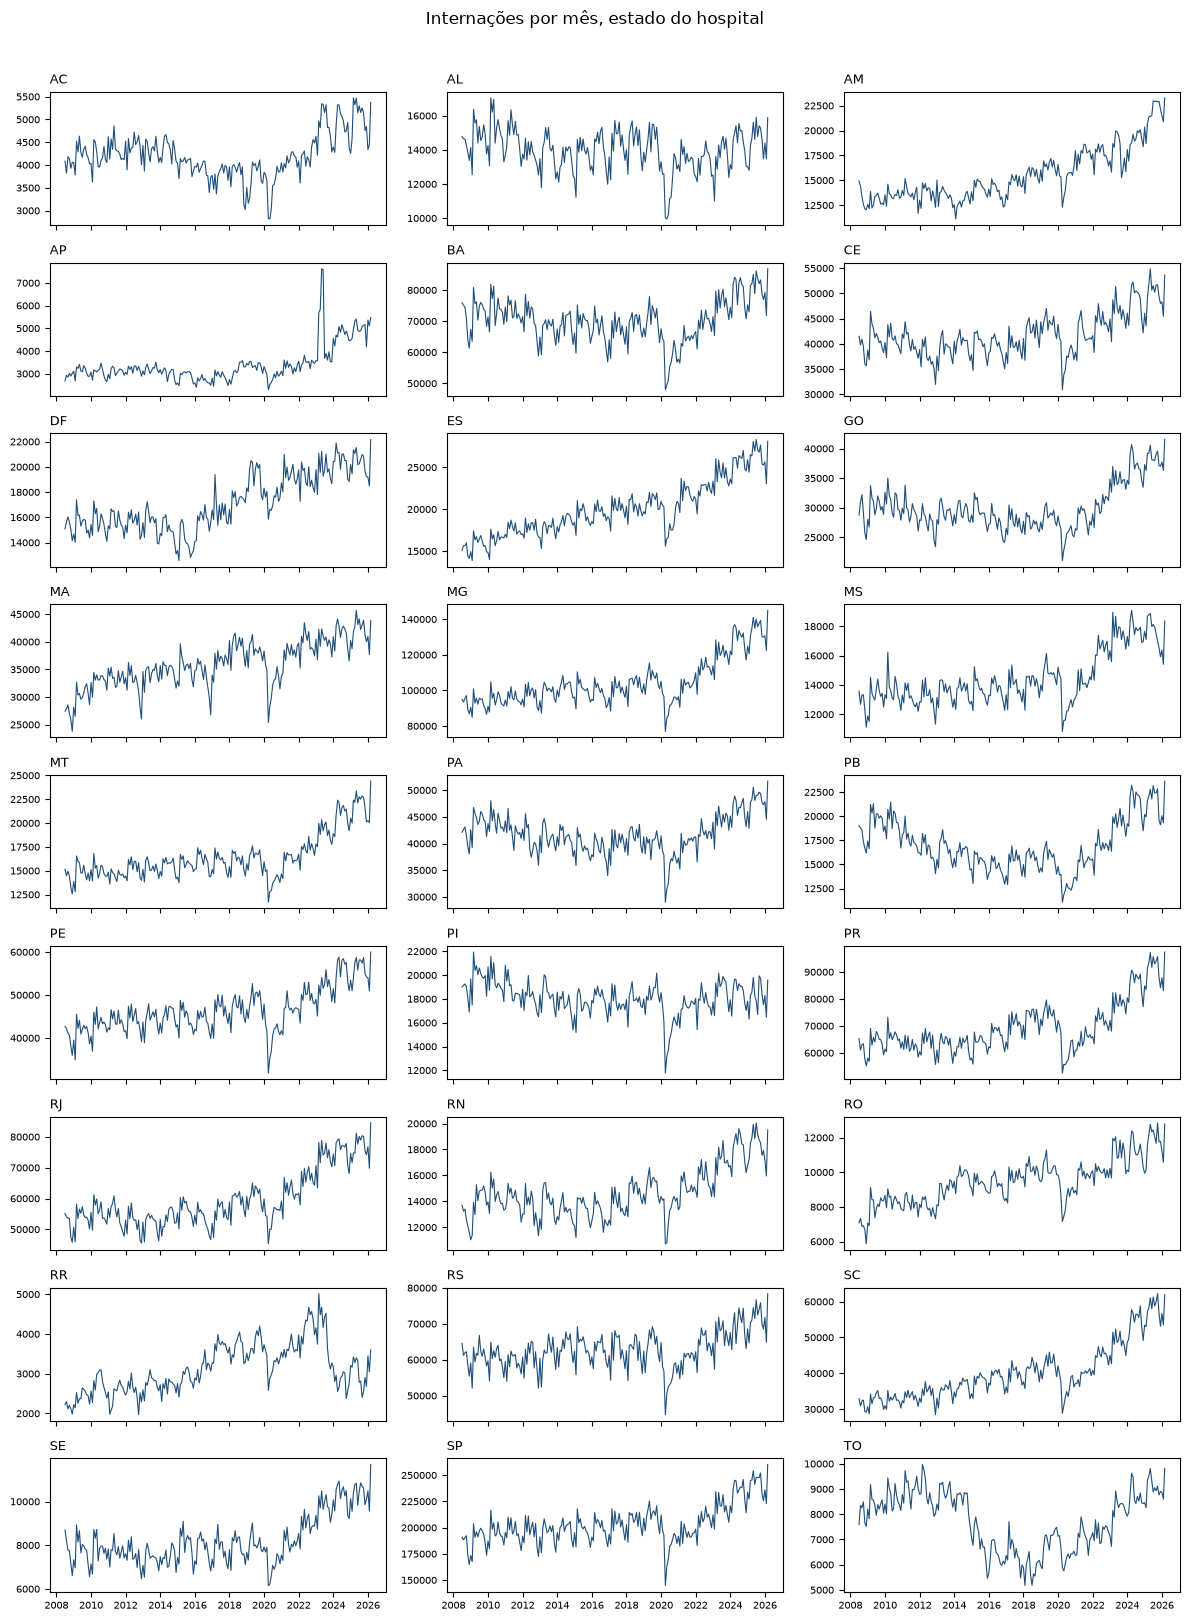

In [8]:
fig, eixos = plt.subplots(9, 3, figsize=(12, 16), sharex=True)
for eixo, uf in zip(eixos.ravel(), UFS):
    eixo.plot(confiavel.index, confiavel[uf], color="#1f4e79", linewidth=0.8)
    eixo.set_title(uf, loc="left", fontsize=9)
    eixo.tick_params(labelsize=7)
fig.suptitle("Internações por mês, estado do hospital", y=1.01)
fig.tight_layout()
fig.savefig(PASTA / "serie_por_estado.png", dpi=120, bbox_inches="tight")
plt.show()

## LSTM

Um único modelo atende os 27 estados. Cada exemplo é uma janela de 24 meses de um estado. As entradas de cada mês são a quantidade padronizada daquele estado, o seno e o cosseno do mês do ano. A saída são os 12 meses seguintes.

A avaliação usa abril de 2025 a março de 2026, que o treino não vê. A previsão publicada é outra estimação, feita com a série confiável inteira, para abril de 2026 a março de 2027.

In [9]:
class EscalaEstado:
    def __init__(self, treino: pd.DataFrame):
        self.minimo = treino.min()
        self.maximo = treino.max().clip(lower=self.minimo + 1)

    def aplicar(self, valores: pd.DataFrame) -> pd.DataFrame:
        return (valores - self.minimo) / (self.maximo - self.minimo)

    def desfazer(self, uf: str, valores: np.ndarray) -> np.ndarray:
        saida = valores * (self.maximo[uf] - self.minimo[uf]) + self.minimo[uf]
        return np.clip(saida, 0, None)


def calendario(indice: pd.DatetimeIndex) -> np.ndarray:
    angulo = 2 * np.pi * indice.month.to_numpy() / 12
    return np.column_stack([np.sin(angulo), np.cos(angulo)])


def montar_janelas(escalado: pd.DataFrame, t_inicial: int, t_final: int):
    cal = calendario(escalado.index)
    entradas, saidas, estados = [], [], []
    for uf in escalado.columns:
        serie_uf = escalado[uf].to_numpy(dtype=np.float32)
        for t in range(t_inicial, t_final + 1):
            quantidade = serie_uf[t - JANELA : t][:, None]
            entradas.append(np.hstack([quantidade, cal[t - JANELA : t]]))
            saidas.append(serie_uf[t : t + HORIZONTE])
            estados.append(uf)
    x = torch.tensor(np.stack(entradas), dtype=torch.float32)
    y = torch.tensor(np.stack(saidas), dtype=torch.float32)
    return x, y, estados


class LSTMInternacoes(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=3, hidden_size=64, batch_first=True)
        self.saida = nn.Linear(64, HORIZONTE)

    def forward(self, x):
        sequencia, _ = self.lstm(x)
        return self.saida(sequencia[:, -1, :])


def treinar(x, y, epocas=40):
    modelo = LSTMInternacoes()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    perda = nn.MSELoss()
    modelo.train()
    for epoca in range(1, epocas + 1):
        otimizador.zero_grad()
        erro = perda(modelo(x), y)
        erro.backward()
        otimizador.step()
        if epoca == 1 or epoca % 10 == 0:
            print(f"época {epoca:02d}  erro {erro.item():.5f}")
    modelo.eval()
    return modelo

In [10]:
n_meses = len(confiavel)
t_teste = n_meses - HORIZONTE
escala_avaliacao = EscalaEstado(confiavel.iloc[:t_teste])
escalado_avaliacao = escala_avaliacao.aplicar(confiavel)

x_treino, y_treino, _ = montar_janelas(
    escalado_avaliacao, JANELA, t_teste - HORIZONTE
)
x_teste, y_teste, ufs_teste = montar_janelas(
    escalado_avaliacao, t_teste, t_teste
)
print(f"Treino: {len(x_treino):,} janelas. Teste: {len(x_teste)} estados.")

modelo_teste = treinar(x_treino, y_treino)
with torch.no_grad():
    previsto_teste = modelo_teste(x_teste).numpy()

meses_teste = confiavel.index[-HORIZONTE:]
linhas = []
for i, uf in enumerate(ufs_teste):
    real = confiavel[uf].iloc[-HORIZONTE:].to_numpy()
    previsto = np.rint(escala_avaliacao.desfazer(uf, previsto_teste[i])).astype(int)
    linhas.append(
        {
            "uf": uf,
            "mae": np.mean(np.abs(previsto - real)),
            "mape_%": np.mean(np.abs(previsto - real) / np.maximum(real, 1)) * 100,
        }
    )
avaliacao = pd.DataFrame(linhas).set_index("uf")
print(
    f"MAE médio {avaliacao['mae'].mean():,.0f} internações/mês. "
    f"MAPE médio {avaliacao['mape_%'].mean():.1f}%"
)
avaliacao.round(1)

Treino: 4,482 janelas. Teste: 27 estados.
época 01  erro 0.27281
época 10  erro 0.20282
época 20  erro 0.07713
época 30  erro 0.03949
época 40  erro 0.03775
MAE médio 9,252 internações/mês. MAPE médio 19.2%


,mae,mape_%
uf,,
AC,958.8,18.7
AL,1645.8,10.9
AM,6421.8,28.8
AP,458.0,8.9
BA,15772.9,19.2
CE,9509.4,18.6
DF,3257.4,15.8
ES,6230.0,23.3
GO,7991.2,20.7


In [11]:
escala_final = EscalaEstado(confiavel)
escalado_final = escala_final.aplicar(confiavel)
x_final, y_final, _ = montar_janelas(
    escalado_final, JANELA, n_meses - HORIZONTE
)
modelo_final = treinar(x_final, y_final)

cal = calendario(confiavel.index)
ultimas = []
for uf in confiavel.columns:
    quantidade = escalado_final[uf].to_numpy(dtype=np.float32)[-JANELA:, None]
    ultimas.append(np.hstack([quantidade, cal[-JANELA:]]))
x_futuro = torch.tensor(np.stack(ultimas), dtype=torch.float32)

with torch.no_grad():
    bruto = modelo_final(x_futuro).numpy()

meses_futuros = pd.date_range(
    confiavel.index.max() + pd.DateOffset(months=1), periods=HORIZONTE, freq="MS"
)
previsao = pd.DataFrame(index=meses_futuros, columns=list(UFS), dtype=int)
for i, uf in enumerate(confiavel.columns):
    previsao[uf] = np.rint(escala_final.desfazer(uf, bruto[i])).astype(int)

previsao.to_parquet(PASTA / "previsao_12m.parquet")
print(f"Previsão de {previsao.index.min():%Y-%m} a {previsao.index.max():%Y-%m}")
previsao

época 01  erro 0.23018
época 10  erro 0.17398
época 20  erro 0.08055
época 30  erro 0.03756
época 40  erro 0.03369
Previsão de 2026-04 a 2027-03


,AC,AL,AM,AP,BA,CE,DF,ES,GO,MA,...,PR,RJ,RN,RO,RR,RS,SC,SE,SP,TO
2026-04-01,4257,13668,17894,4968,69265,43891,17783,21819,32326,35707,...,77167,66711,15776,9709,3426,63061,47098,9155,208012,7789
2026-05-01,4161,13403,17492,4768,67891,43033,17435,21315,31618,34943,...,75591,65320,15441,9467,3304,61860,45939,8955,203939,7620
2026-06-01,4310,13712,18279,4923,70196,44357,17974,22198,32845,36208,...,78292,67589,15965,9893,3344,63782,48037,9255,210755,7893
2026-07-01,4178,13401,17618,4729,68180,43165,17490,21441,31776,35104,...,75951,65574,15500,9526,3254,62064,46248,8978,204784,7650
2026-08-01,4235,13609,17809,4930,68954,43699,17701,21709,32165,35548,...,76811,66390,15702,9656,3401,62783,46845,9107,207079,7751
2026-09-01,4278,13703,17991,4986,69549,44053,17843,21942,32458,35896,...,77500,66959,15852,9763,3421,63268,47366,9180,208804,7818
2026-10-01,4202,13443,17739,4743,68542,43366,17572,21586,31958,35308,...,76376,65915,15585,9593,3250,62352,46578,9020,205833,7689
2026-11-01,4055,13125,16990,4560,66328,42074,17055,20732,30791,34058,...,73786,63745,15068,9183,3190,60512,44568,8734,199309,7427
2026-12-01,4043,13091,16931,4535,66140,41958,17006,20666,30684,33961,...,73565,63546,15026,9150,3173,60342,44404,8704,198725,7402
2027-01-01,4292,13711,18133,4969,69842,44197,17897,22062,32636,36055,...,77860,67243,15905,9825,3391,63498,47683,9212,209676,7853


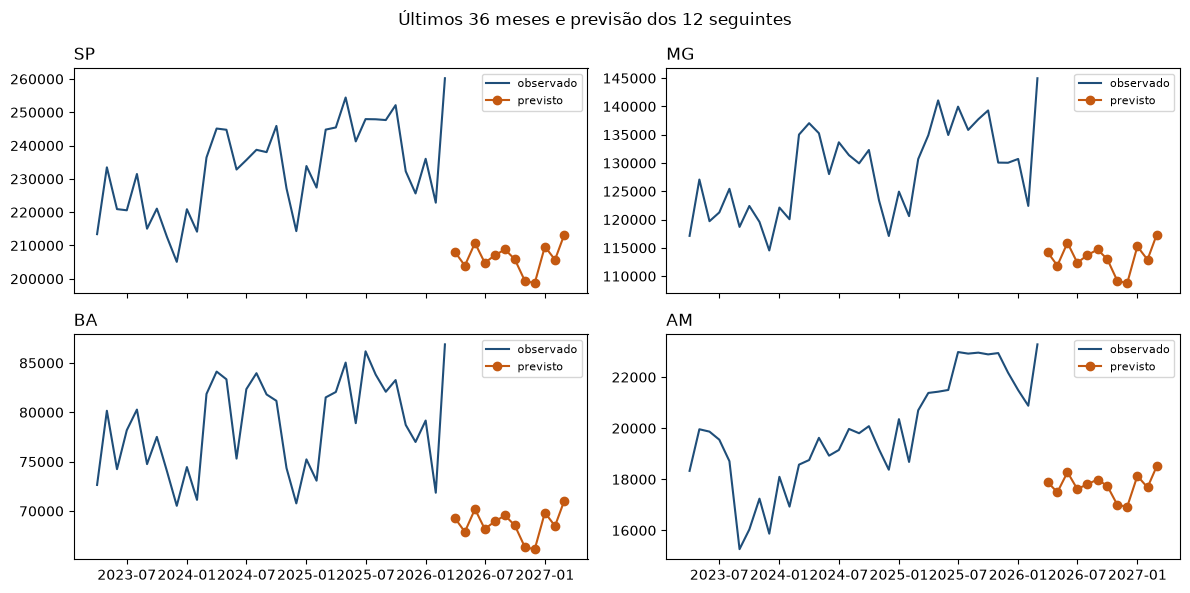

In [12]:
fig, eixos = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for eixo, uf in zip(eixos.ravel(), ["SP", "MG", "BA", "AM"]):
    historia = confiavel[uf].iloc[-36:]
    eixo.plot(historia.index, historia, color="#1f4e79", label="observado")
    eixo.plot(
        previsao.index,
        previsao[uf],
        color="#c45911",
        marker="o",
        label="previsto",
    )
    eixo.set_title(uf, loc="left")
    eixo.legend(fontsize=8)
fig.suptitle("Últimos 36 meses e previsão dos 12 seguintes")
fig.tight_layout()
fig.savefig(PASTA / "previsao_exemplos.png", dpi=120, bbox_inches="tight")
plt.show()